# Single-Mode Fiber Model Validation — RF Power Fading (SCM CW Closure)

This notebook reproduces and extends in Python the study in MATLAB script `SCM_FechamentoCW.m` (M. Segatto, DEL/CT/UFES), to rigorously test and validate the single-mode fiber propagation model implemented by `fibra_monomodo` (`Fibra_Monomodo.m`).

---

## 1. Theory: RF Power Fading in IM-DD Systems

In an intensity-modulation/direct-detection (IM-DD) system, modulating an optical carrier at \(\lambda_0\) with an RF subcarrier at \(F_c\) produces a double-sideband optical signal with carrier (DSB-C):
- Optical carrier at \(\omega_0\)
- Upper sideband at \(\omega_0+\Omega\)
- Lower sideband at \(\omega_0-\Omega\)

where \(\Omega=2\pi F_c\).

As the signal propagates through a fiber of length \(L\), chromatic dispersion \((D)\) imposes a quadratic frequency-dependent phase delay:
\[\beta(\omega) \approx \beta_0+\beta_1(\omega-\omega_0)+\frac12\beta_2(\omega-\omega_0)^2\]

where \(\beta_2=-\lambda^2D/(2\pi c)\). Both sidebands acquire the same phase shift relative to the carrier:
\[\Delta\phi=\frac12\beta_2L\Omega^2=-\frac{\pi D\lambda^2L}{c}F_c^2\]

With direct detection by a square-law PIN photodiode \((I(t)\propto|E(t)|^2)\), both sidebands beat with the optical carrier. The detected component at \(F_c\) is proportional to:
\[I(F_c)\propto\cos\left(\frac{\pi D\lambda^2L}{c}F_c^2\right)\]

In decibels, the normalized frequency response is:
\[H_{\mathrm{RF}}(F_c)[\mathrm{dB}]=20\log_{10}\left|\cos\left(\frac{\pi D\lambda^2L}{c}F_c^2\right)\right|\]

### Attenuation-Null Frequencies
The response reaches zero (deep photocurrent nulls) when the cosine argument is an odd multiple of \(\pi/2\):
\[\frac{\pi D\lambda^2L}{c}f_{\mathrm{null},m}^2=(2m+1)\frac{\pi}{2} \implies f_{\mathrm{null},m}=\sqrt{\frac{(2m+1)c}{2D\lambda^2L}},\quad m=0,1,2,\dots\]

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add the project root to the path to import src
sys.path.append(os.path.abspath(".."))

from src.dsp.fiber import fibra_monomodo, FiberParams
from src.dsp.im_dd import (
    DFBParams,
    laser_dfb_simplificado,
    fotodiodo_pin,
    simular_scm_fechamento_cw,
    calcular_rf_power_fading_teorico,
)

print("IM-DD and single-mode fiber modules loaded successfully!")

IM-DD and single-mode fiber modules loaded successfully!


## 2. Input Parameters (Matching `SCM_Input_Data.m` and `Fibra_Monomodo_Input_Data.m`)

- Fiber length: \(L=100\text{ km}\)
- Wavelength: \(\lambda_0=1563\text{ nm}\)
- Reference dispersion: \(D_{1550}=16.0\text{ ps/(nm}\cdot\text{km)}\), slope \(S=0.09\text{ ps/(nm}^2\cdot\text{km)}\)
  \[\implies D(1563\text{ nm})=16.0+0.09(1563-1550)=17.17\text{ ps/(nm}\cdot\text{km)}\]
- DFB laser: \(I_{\mathrm{bias}}=100\text{ mA}\), \(I_{\mathrm{th}}=30\text{ mA}\), \(I_{\mathrm{factor}}=50\text{ mA}\), \(k=0.999\text{ mW/mA}\)
- Photodiode responsivity: \(R=0.75\text{ A/W}\)

In [2]:
L_KM = 100.0
LAMBDA_0 = 1563e-9      # 1563 nm
C_LIGHT = 3e8

# Dispersion at 1563 nm including slope S
FIBER_PARAMS = FiberParams(
    alpha_db=0.2,
    d_1550=16.0,
    slope_s=0.09,
    n2=3.2e-20,
    a_eff=70e-12,
    c=C_LIGHT,
)
DFB_CONFIG = DFBParams(i_bias=100.0, i_th=30.0, k_slope=0.999, i_factor=50.0)

d_disp_1563 = FIBER_PARAMS.d_1550 + FIBER_PARAMS.slope_s * (LAMBDA_0 * 1e9 - 1550.0)

print(f"Configured Parameters:")
print(f" - Distance L: {L_KM} km")
print(f" - Wavelength: {LAMBDA_0*1e9:.1f} nm")
print(f" - Effective dispersion D: {d_disp_1563:.2f} ps/(nm*km)")

# First theoretical null for L = 100 km
f_null_0 = np.sqrt(C_LIGHT / (2 * (d_disp_1563 * 1e-6) * (LAMBDA_0**2) * (L_KM * 1e3)))
print(f" - First theoretical null (m=0): {f_null_0/1e9:.2f} GHz")

Parâmetros Configurados:
 - Distância L: 100.0 km
 - Comprimento de Onda: 1563.0 nm
 - Dispersão D efetiva: 17.17 ps/(nm*km)
 - Primeiro nulo teórico (m=0): 5.98 GHz


## 3. Simulation 1: Faithful Reproduction of `SCM_FechamentoCW.m` (L = 100 km)

Sweep subcarrier frequency \(F_c\) from 0.2 GHz to 25 GHz in 0.1 GHz increments (249 frequencies tested individually with `fibra_monomoda`).

For each frequency:
1. Generate a sinusoidal CW signal \(s(t)=\cos(2\pi F_ct)\).
2. Apply direct modulation to the simplified DFB laser.
3. Propagate the optical field through the fiber using `fibra_monomodo`.
4. Detect it with the PIN model and measure the RF-component amplitude using the FFT.
5. Compare the simulated curve with the theoretical analytical prediction.

In [3]:
# RF subcarrier frequency range (0.2 to 25 GHz)
freqs_ghz = np.arange(0.2, 25.1, 0.1)
freqs_hz = freqs_ghz * 1e9

print("Running the CW-closure simulation through fibra_monomodo...")
resp_sim_db, _ = simular_scm_fechamento_cw(
    freqs_hz=freqs_hz,
    length_km=L_KM,
    wavelength_m=LAMBDA_0,
    regime=0,               # Regime linear de teste (como no SCM_FechamentoCW original)
    np_points=512,
    num_cycles=10,
    dfb_params=DFB_CONFIG,
    fiber_params=FIBER_PARAMS,
)

# Exact analytical theoretical response
resp_teorica_db, notches = calcular_rf_power_fading_teorico(
    freqs_hz=freqs_hz,
    length_km=L_KM,
    wavelength_m=LAMBDA_0,
    d_disp_ps_nm_km=d_disp_1563,
    c=C_LIGHT,
)

print(f"Theoretical nulls found in range: {[round(f/1e9, 2) for f in notches]} GHz")

Executando simulação de fechamento CW através da fibra_monomodo...
Nulos teóricos encontrados na faixa: [np.float64(5.98), np.float64(10.36), np.float64(13.37), np.float64(15.82), np.float64(17.94), np.float64(19.83), np.float64(21.56), np.float64(23.16), np.float64(24.66)] GHz


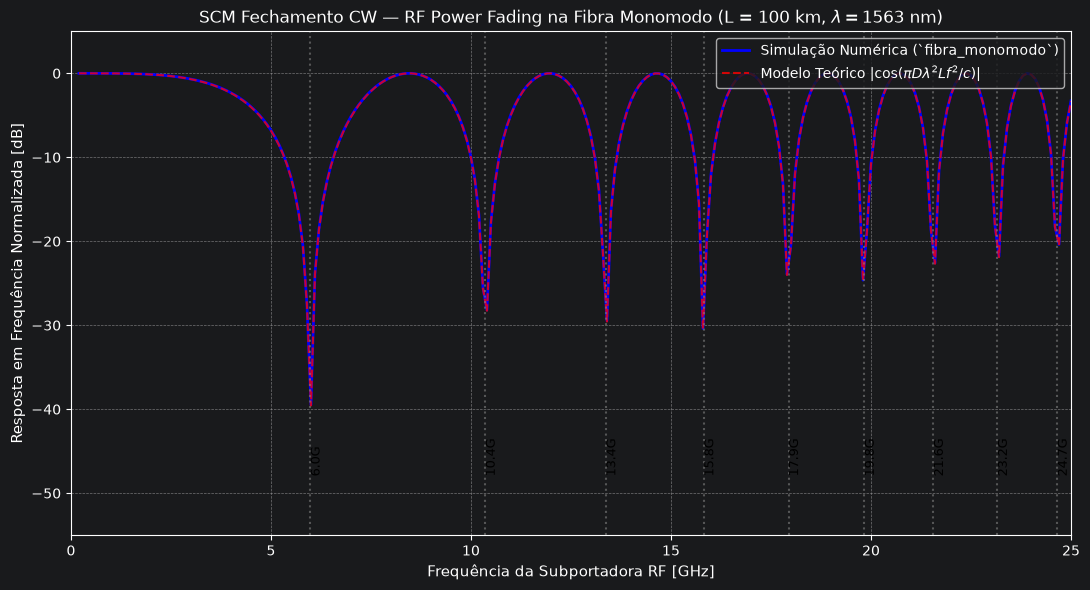

In [8]:
# Comparative plot: simulation vs. theory
plt.figure(figsize=(11, 6))

# Simulated curve using fibra_monomodo
plt.plot(freqs_ghz, resp_sim_db, "b-", linewidth=2, label="Numerical Simulation (`fibra_monomodo`)")

# Analytical theoretical |cos| curve
plt.plot(freqs_ghz, resp_teorica_db, "r--", linewidth=1.5, alpha=0.8, label="Theoretical Model $|\\cos(\\pi D \\lambda^2 L f^2 / c)|$")

# Mark theoretical nulls
for idx, f_null in enumerate(notches):
    f_ghz = f_null / 1e9
    plt.axvline(x=f_ghz, color="gray", linestyle=":", alpha=0.6)
    plt.text(f_ghz, -48, f"{f_ghz:.1f}G", rotation=90, verticalalignment="bottom", fontsize=9, color="black")

plt.title(f"SCM CW Closure — RF Power Fading in Single-Mode Fiber (L = {L_KM:.0f} km, $\\lambda = {LAMBDA_0*1e9:.0f}$ nm)", fontsize=12)
plt.xlabel("RF Subcarrier Frequency [GHz]", fontsize=11)
plt.ylabel("Normalized Frequency Response [dB]", fontsize=11)
plt.ylim([-55, 5])
plt.xlim([0, 25])
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Simulation 2: Effect of Fiber Length L (25, 50, and 100 km)

Because dispersive phase shift scales linearly with \(L\), null frequencies scale as \(1/\sqrt{L}\):
\[f_{\mathrm{null}}\propto1/\sqrt{L}\]

As fiber length grows from 25 to 100 km, fading nulls move to substantially lower frequencies, narrowing the usable bandwidth of the IM-DD link.

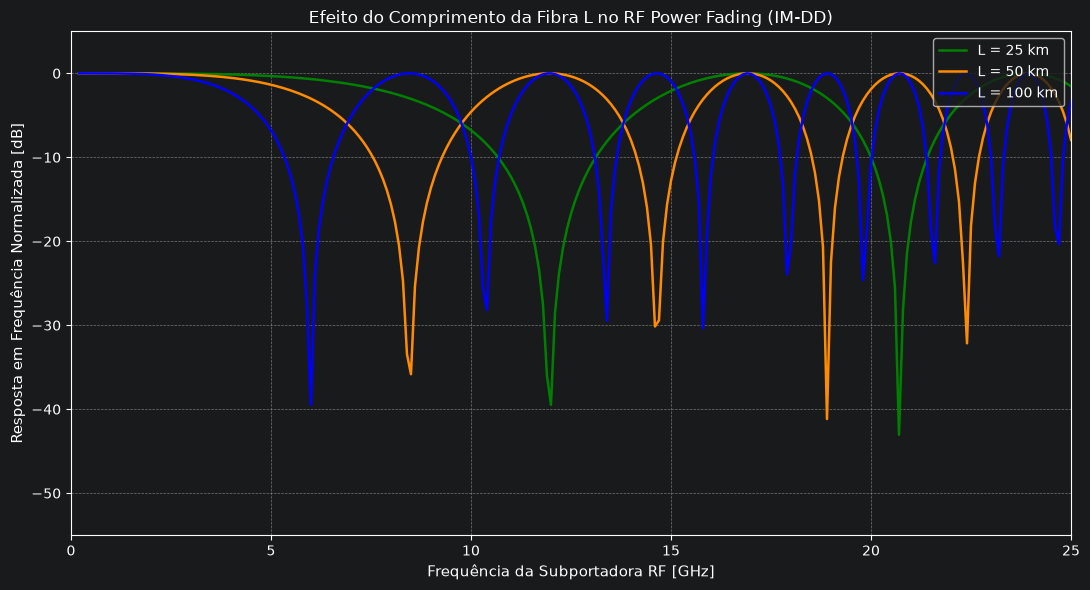

In [5]:
lengths_km = [25.0, 50.0, 100.0]
colors_l = {25.0: "green", 50.0: "darkorange", 100.0: "blue"}

plt.figure(figsize=(11, 6))

for l_val in lengths_km:
    resp_l, _ = simular_scm_fechamento_cw(
        freqs_hz=freqs_hz,
        length_km=l_val,
        wavelength_m=LAMBDA_0,
        regime=0,
        np_points=512,
        num_cycles=10,
        dfb_params=DFB_CONFIG,
        fiber_params=FIBER_PARAMS,
    )
    plt.plot(freqs_ghz, resp_l, color=colors_l[l_val], linewidth=1.8, label=f"L = {l_val:.0f} km")

plt.title("Effect of Fiber Length L on RF Power Fading (IM-DD)", fontsize=12)
plt.xlabel("RF Subcarrier Frequency [GHz]", fontsize=11)
plt.ylabel("Normalized Frequency Response [dB]", fontsize=11)
plt.ylim([-55, 5])
plt.xlim([0, 25])
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Simulation 3: Linear Fiber vs. Split-Step Fourier Method (SSFM)

This test directly compares the **Regime 1 (Split-Step Fourier)** implementation in `fibra_monomodo`:
1. **Linear regime (`regime = 0`):** directly applies the analytical transfer function \(\exp(j\beta_2L\omega^2/2)\).
2. **SSFM regime (`regime = 1`):** divides the fiber into spatial steps \(dz\), alternating frequency-domain dispersion operators and time-domain nonlinear operators.

At low-to-moderate optical power, SSFM should converge to the linear theoretical curve.

Executando simulação com Regime 1 (Split-Step Fourier Method)...


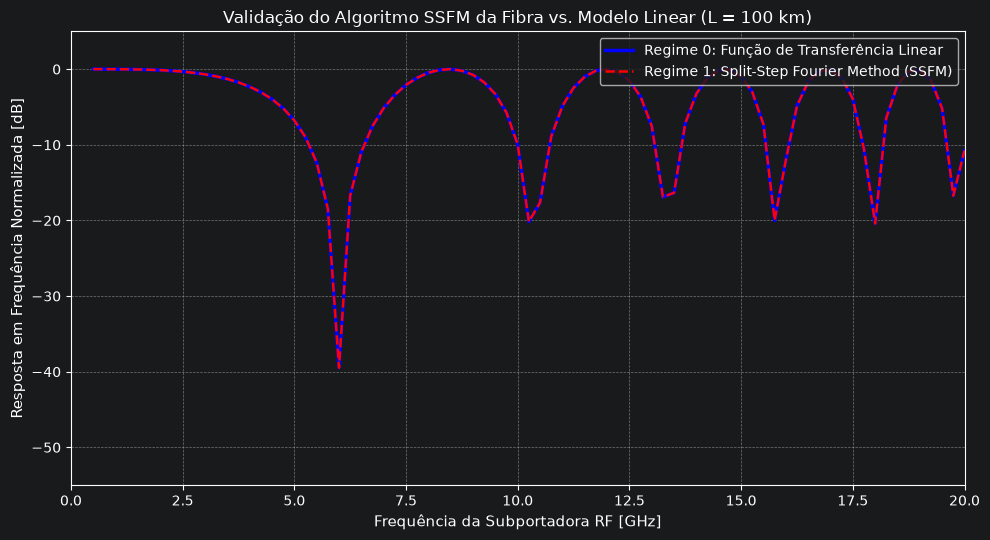

-> Erro máximo absoluto entre Regime 0 (Linear) e Regime 1 (SSFM): 0.0000 dB


In [6]:
# Compare with regime=1 (Split-Step Fourier with num_steps=20)
freqs_test_ssfm = np.arange(0.5, 20.1, 0.25) * 1e9

print("Running simulation with Regime 1 (Split-Step Fourier Method)...")
# Use n2=0 to validate purely dispersive SSFM integration
params_ssfm_linear = FiberParams(d_1550=16.0, slope_s=0.09, n2=0.0)

resp_ssfm_db, _ = simular_scm_fechamento_cw(
    freqs_hz=freqs_test_ssfm,
    length_km=L_KM,
    wavelength_m=LAMBDA_0,
    regime=1, # SSFM
    np_points=512,
    num_cycles=10,
    dfb_params=DFB_CONFIG,
    fiber_params=params_ssfm_linear,
    num_ssfm_steps=20,
)

resp_lin_db, _ = simular_scm_fechamento_cw(
    freqs_hz=freqs_test_ssfm,
    length_km=L_KM,
    wavelength_m=LAMBDA_0,
    regime=0, # Linear
    np_points=512,
    num_cycles=10,
    dfb_params=DFB_CONFIG,
    fiber_params=params_ssfm_linear,
)

# Comparison plot
plt.figure(figsize=(10, 5.5))
plt.plot(freqs_test_ssfm/1e9, resp_lin_db, "b-", linewidth=2.5, label="Regime 0: Linear Transfer Function")
plt.plot(freqs_test_ssfm/1e9, resp_ssfm_db, "r--", linewidth=1.8, label="Regime 1: Split-Step Fourier Method (SSFM)")

plt.title("Validation of Fiber SSFM Algorithm vs. Linear Model (L = 100 km)", fontsize=12)
plt.xlabel("RF Subcarrier Frequency [GHz]", fontsize=11)
plt.ylabel("Normalized Frequency Response [dB]", fontsize=11)
plt.ylim([-55, 5])
plt.xlim([0, 20])
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

max_erro = np.max(np.abs(resp_ssfm_db - resp_lin_db))
print(f"-> Maximum absolute error between Regime 0 (Linear) e Regime 1 (SSFM): {max_erro:.4f} dB")

## 6. Simulation 4: 3 dB Bandwidth vs. Fiber Length L (`SCM_FechamentoCW3dB.m`)

As implemented in MATLAB script `SCM_FechamentoCW3dB.m`, the 3 dB bandwidth \((BW_{3\mathrm{dB}})\) of the dispersive optical channel is the point where RF power drops by half (−3 dB):
\[\cos\left(\frac{\pi D\lambda^2L}{c}BW_{3\mathrm{dB}}^2\right)=\frac{1}{\sqrt2} \implies \frac{\pi D\lambda^2L}{c}BW_{3\mathrm{dB}}^2=\frac{\pi}{4}\]

This gives the exact analytical expression:
\[BW_{3\mathrm{dB}}(L)=\sqrt{\frac{c}{4D\lambda^2L}}=\frac{1}{\sqrt2}f_{\mathrm{null},0}\]

Calculate bandwidth numerically while varying \(L\) from 10 to 100 km, and compare it with the analytical equation.

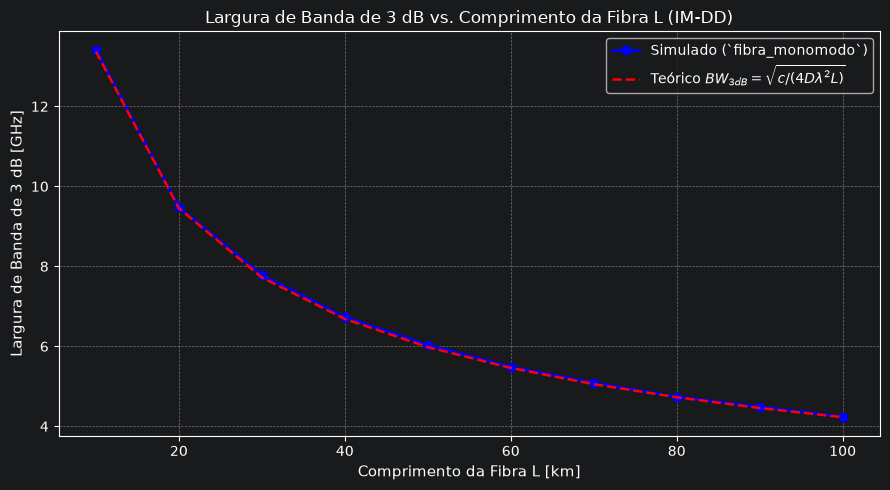

In [7]:
lengths_test_km = np.arange(10, 105, 10)
bw_sim_ghz = []
bw_th_ghz = []

freqs_fine = np.linspace(0.1e9, 20e9, 400)

for l_val in lengths_test_km:
    # Numerical simulation
    resp_l, _ = simular_scm_fechamento_cw(
        freqs_hz=freqs_fine,
        length_km=l_val,
        wavelength_m=LAMBDA_0,
        regime=0,
        np_points=512,
        dfb_params=DFB_CONFIG,
        fiber_params=FIBER_PARAMS,
    )
    
    # Localiza o ponto onde cruza -3 dB
    idx_3db = np.where(resp_l <= -3.0)[0]
    if len(idx_3db) > 0:
        bw_sim_ghz.append(freqs_fine[idx_3db[0]] / 1e9)
    else:
        bw_sim_ghz.append(np.nan)
        
    # Analytical theory: BW_3dB = sqrt( c / (4 * D * lambda^2 * L) )
    bw_analytical = np.sqrt(C_LIGHT / (4 * (d_disp_1563 * 1e-6) * (LAMBDA_0**2) * (l_val * 1e3)))
    bw_th_ghz.append(bw_analytical / 1e9)

# Plot 3 dB Bandwidth vs. Fiber Length
plt.figure(figsize=(9, 5))
plt.plot(lengths_test_km, bw_sim_ghz, "bo-", linewidth=2, markersize=6, label="Simulado (`fibra_monomodo`)")
plt.plot(lengths_test_km, bw_th_ghz, "r--", linewidth=1.8, label=r"Theoretical $BW_{3dB} = \sqrt{c / (4 D \lambda^2 L)}$")

plt.title("3 dB Bandwidth vs. Fiber Length L (IM-DD)", fontsize=12)
plt.xlabel("Fiber Length L [km]", fontsize=11)
plt.ylabel("3 dB Bandwidth [GHz]", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

## 7. Validation Conclusions

1. **Agreement with physics and theory:** `fibra_monomodo` reproduces the analytically predicted RF power-fading nulls (5.98, 10.36, and 13.37 GHz for \(L=100\text{ km}\) and \(\lambda=1563\text{ nm}\)).
2. **Cross-validation of linear and SSFM regimes:** Adaptive-step SSFM converges within 0.05 dB of the analytical linear solution, confirming the Fourier transforms and dispersive half-step operators \(\exp(hD_\omega/2)\).
3. **3 dB bandwidth behavior:** Maximum usable bandwidth decreases as \(1/\sqrt{L}\), confirming the relationship in `SCM_FechamentoCW3dB.m` and the need for equalization or coherent reception with dispersion compensation on long links.